In [1]:
import pandas as pd
import requests
from bs4 import BeautifulSoup
import numpy as np

In [2]:
headers={'User-Agent':'Mozilla/5.0 (Windows NT 6.3; Win 64 ; x64) Apple WeKit /537.36(KHTML , like Gecko) Chrome/80.0.3987.162 Safari/537.36'}
webpage = requests.get('https://www.ambitionbox.com/list-of-companies?page=1',headers=headers).text

In [3]:
soup=BeautifulSoup(webpage,'html.parser')

<!DOCTYPE html>
<html lang="en">
 <head>
  <meta charset="utf-8"/>
  <title>
   Top Companies in India | AmbitionBox
  </title>
  <meta content="Top Companies in India | AmbitionBox" name="title"/>
  <meta content="Get detailed information of top Companies in India shared by employees through reviews, salaries, interview questions, benefits and more." name="description"/>
  <meta content="width=device-width,initial-scale=1, minimum-scale=1, interactive-widget=resizes-content" name="viewport"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_16x16.png" rel="icon" sizes="16x16" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_32x32.png" rel="icon" sizes="32x32" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/browser_icon_48x48.png" rel="icon" sizes="48x48" type="image/png"/>
  <link href="https://static.ambitionbox.com/alpha/img/supporting-images/brows
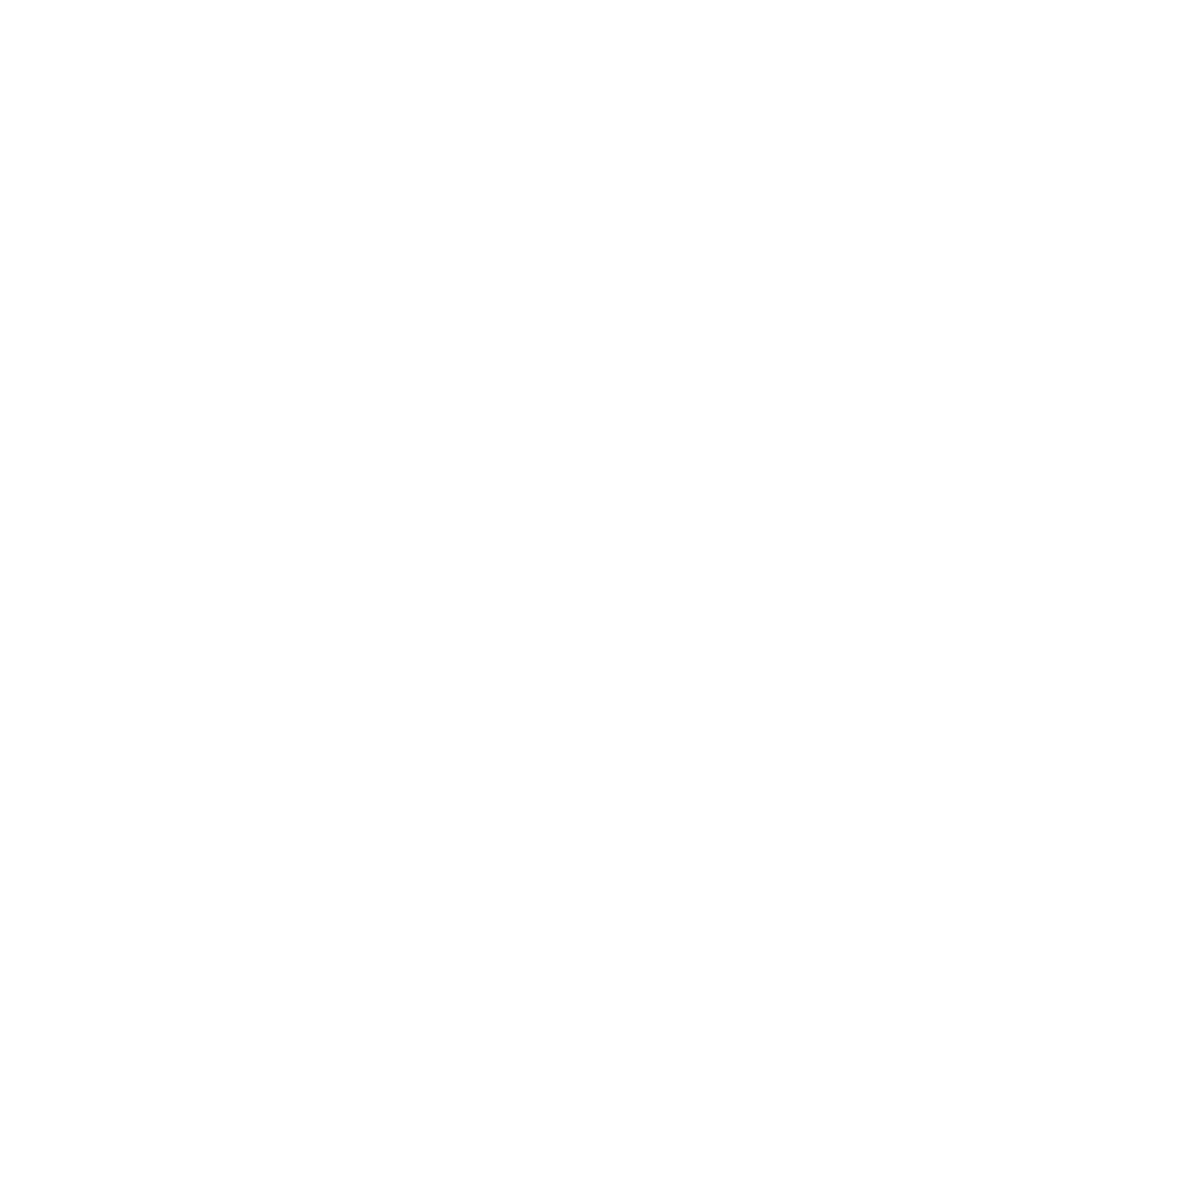

In [4]:
print(soup.prettify())

In [5]:
h2_tags= soup.find_all('h2')
for tag in h2_tags:
    print(tag.text)

TCS
Accenture
Wipro
Cognizant
Capgemini
HDFC Bank
Infosys
HCLTech
ICICI Bank
Tech Mahindra
Genpact
TP 
Axis Bank
Concentrix Corporation
Jio
Amazon
Reliance Retail
LTM Limited
HDB Financial Services
iEnergizer


In [6]:
len(soup.find_all('span',class_='text-primary-text'))
    

26

In [7]:
len(soup.find_all('span',class_='pl-1'))

20

In [8]:
company=soup.find_all('div',class_='flex cursor-pointer px-5 pt-5 gap-2 max-md:px-3 max-md:pt-4')

In [9]:
len(company)

20

In [10]:
# Poora company card (parent container) nikalna
if company[0].parent.find('a', href=lambda x: x and '/jobs/' in x):
    full_company = [c.parent for c in company]
else:
    full_company = [c.parent.parent for c in company]

# Kisi bhi stat link (salaries, interviews, jobs, benefits, photos) se number nikalne ka helper
def get_stat(card, keyword):
    tag = card.find('a', href=lambda x: x and keyword in x)
    span = tag.find('span') if tag else None
    return span.text.strip() if span else None

name = []
rating = []
reviews = []
salary = []
interviews = []
jobs = []
benefits = []
photos = []

for i in full_company:
    n = i.find('h2')
    r = i.find('span', class_='text-primary-text font-pn-700 text-sm !text-[14px] !leading-[14px]')
    rev = i.find('span', class_='pl-1 text-[14px] font-pn-400 leading-5 text-[#4E597B] max-md:text-[12px]')

    name.append(n.text.strip() if n else None)
    rating.append(r.text.strip() if r else None)
    reviews.append(rev.text.strip() if rev else None)
    salary.append(get_stat(i, '/salaries/'))
    interviews.append(get_stat(i, '/interviews/'))
    jobs.append(get_stat(i, '/jobs/'))
    benefits.append(get_stat(i, '/benefits/'))
    photos.append(get_stat(i, '/photos/'))

df = pd.DataFrame({
    'Name': name,
    'Rating': rating,
    'Reviews': reviews,
    'Salaries': salary,
    'Interviews': interviews,
    'Jobs': jobs,
    'Benefits': benefits,
    'Photos': photos
})

df

,Name,Rating,Reviews,Salaries,Interviews,Jobs,Benefits,Photos
0,TCS,3.2,(1.3L),10.6L,11.8k,716,12.4k,102
1,Accenture,3.7,(84.4k),7.4L,9.9k,16.6k,8k,50
2,Wipro,3.6,(73.3k),5L,7.3k,676,5.7k,125
3,Cognizant,3.6,(69.2k),6.1L,6.8k,1.2k,6.4k,107
4,Capgemini,3.6,(61.2k),5L,5.9k,2.8k,4.5k,57
5,HDFC Bank,3.7,(60.9k),1.6L,3.5k,713,4.4k,147
6,Infosys,3.5,(55.3k),5.4L,8.8k,4.9k,5.5k,135
7,HCLTech,3.4,(52.3k),4L,4.8k,717,4.5k,90
8,ICICI Bank,3.9,(50.9k),1.6L,3.2k,24,4.3k,86
9,Tech Mahindra,3.2,(49.6k),2.9L,4.9k,719,4k,97


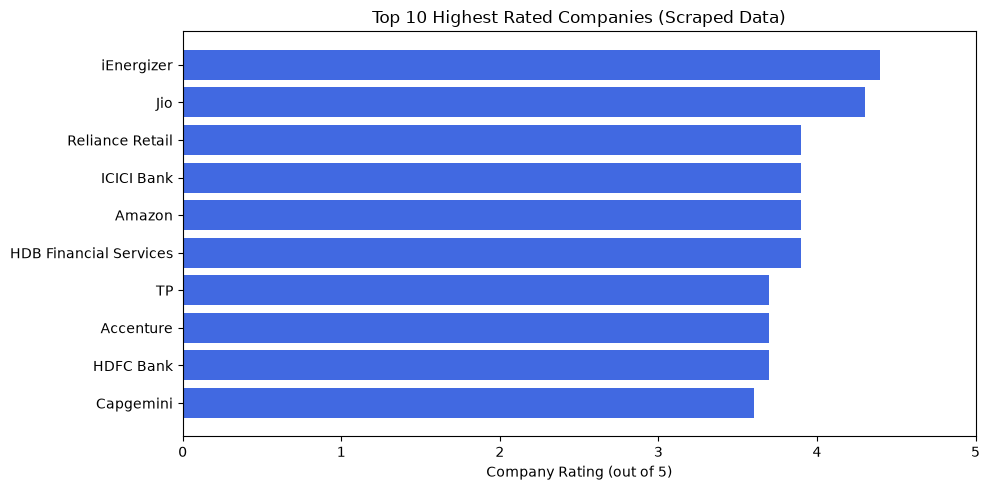

In [11]:
import matplotlib.pyplot as plt

# Reviews se brackets hatana aur Rating ko decimal number banana
df['Reviews'] = df['Reviews'].str.replace('(', '', regex=False).str.replace(')', '', regex=False)
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

# Scraped data ko CSV file me save karna
df.to_csv('ambitionbox_companies.csv', index=False)

# Top 10 Highest Rated Companies ka bar chart
top_rated = df.dropna(subset=['Rating']).sort_values(by='Rating', ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.barh(top_rated['Name'][::-1], top_rated['Rating'][::-1], color='royalblue')
plt.xlabel('Company Rating (out of 5)')
plt.title('Top 10 Highest Rated Companies (Scraped Data)')
plt.xlim(0, 5)
plt.tight_layout()
plt.show()